# Proyecto Integrado: Análisis del mercado global de videojuegos (Ice)

## Introducción y objetivo del proyecto

La industria de los videojuegos se caracteriza por una evolución constante en las preferencias de los consumidores, los ciclos de vida de las plataformas y la popularidad de los distintos géneros. Comprender estos factores resulta fundamental para identificar oportunidades comerciales y desarrollar estrategias de marketing basadas en datos.

El objetivo de este proyecto es analizar el comportamiento histórico del mercado global de videojuegos mediante información sobre ventas, plataformas, géneros, calificaciones de usuarios y reseñas de críticos. A partir de estos datos, se busca identificar los factores asociados al desempeño comercial de los videojuegos y las diferencias en las preferencias de los consumidores entre regiones geográficas.

El análisis comprende la exploración y preparación de los datos, la identificación de tendencias históricas, la evaluación de las ventas por plataforma y género, el estudio de las diferencias regionales y la realización de pruebas de hipótesis estadísticas.

Finalmente, se utilizarán los hallazgos del período 2014-2016 para formular recomendaciones comerciales orientadas a la planificación de la campaña publicitaria de 2017, considerando las particularidades de cada mercado y las tendencias observadas en la industria.

## Entorno y dependencias

Este proyecto fue desarrollado utilizando Python y las bibliotecas especializadas para análisis y visualización de datos.

Para reproducir el análisis, es necesario instalar las dependencias especificadas en el archivo `requirements.txt`, ubicado en la carpeta raíz del repositorio.

Desde la terminal, dentro de la carpeta principal del proyecto, ejecutar:

```bash
pip install -r requirements.txt
```

Una vez instaladas las dependencias, se puede abrir el notebook y ejecutar las celdas en orden.

## 1. Importar y explorar el archivo de datos

En esta primera etapa cargamos las librerías necesarias (`pandas`, `numpy`) y el archivo `games.csv` para realizar una inspección inicial de la estructura del dataset, sus dimensiones y tipos de datos.

### Hallazgos preliminares y problemas identificados:

* **Estructura y dimensiones:** El DataFrame cuenta con 16,715 filas y 11 columnas.
* **Nombres de columnas:** Los encabezados presentan mayúsculas y formato mixto, por lo que deberán estandarizarse a minúsculas para mantener una nomenclatura uniforme.
* **Tipos de datos incorrectos o inconsistentes:**
  - La columna `year_of_release` aparece como `float64` debido a la presencia de valores nulos (`NaN`). Se convertirá al tipo `Int64` de pandas, que permite representar números enteros y conservar los valores ausentes.
  - La columna `user_score` está almacenada como `object` (texto) en lugar de numérico, debido, entre otros motivos, a la presencia de etiquetas como `'tbd'` (*To Be Determined*). Será necesario tratar estos valores y convertir la columna a formato numérico.
* **Valores ausentes:** Se observa una cantidad considerable de datos faltantes en columnas clave como `critic_score`, `user_score` y `rating`, los cuales deberán evaluarse y tratarse cuidadosamente durante la preparación de los datos para evitar introducir sesgos en el análisis.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Buscamos el dataset en la carpeta Datasets
# desde el directorio actual y sus carpetas superiores.
current_dir = Path.cwd()

search_locations = [
    current_dir,
    *list(current_dir.parents)[:3]
]

dataset_path = None

for folder in search_locations:
    for dataset_folder in ['Datasets', 'datasets']:
        candidate = folder / dataset_folder / 'games.csv'

        if candidate.is_file():
            dataset_path = candidate
            break

    if dataset_path is not None:
        break

# Verificamos que el archivo haya sido encontrado
if dataset_path is None:
    raise FileNotFoundError(
        "No se encontró games.csv. "
        "Verifica que esté dentro de la carpeta Datasets."
    )

# Cargamos el dataset
df = pd.read_csv(dataset_path)

print(f"Dataset cargado correctamente desde: {dataset_path}")

# Visualizamos las primeras filas
display(df.head())

# Vemos información general sobre tipos de datos y nulos
df.info()

# Estadísticas descriptivas básicas
display(df.describe())

Dataset cargado correctamente desde: c:\Users\The Swarm\Documents\Work-5\TripleTen\5 Proyecto Integrado de Análisis del mercado global de videojuegos Ice)\Datasets\games.csv


,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 1.4 MB


,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,16446.000000,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000
mean,2006.484616,0.263377,0.145060,0.077617,0.047342,68.967679
std,5.877050,0.813604,0.503339,0.308853,0.186731,13.938165
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000


### Problemas identificados en los datos

Al cargar y explorar el archivo inicial (`games.csv`), identificamos los siguientes detalles estructurales y anomalías mediante la inspección general de los datos (`df.info()` y `df.describe()`):

* **Nombres de columnas en mayúsculas:** Los encabezados originales contienen mayúsculas y un formato mixto (por ejemplo, `Year_of_Release`), por lo que deberán estandarizarse a minúsculas para mantener una nomenclatura uniforme.
* **Tipos de datos incorrectos y anomalías en `user_score`:**
  * La columna `year_of_release` aparece como tipo flotante (`float64`) debido a la presencia de valores nulos.
  * La columna `user_score` está almacenada como tipo objeto (`object`), con 10,014 valores no nulos de un total de 16,715 registros. Esto se debe, entre otros motivos, a la presencia de etiquetas de texto como `'tbd'` (*To Be Determined*), además de las puntuaciones numéricas.
* **Valores ausentes específicos según `df.info()`:**
  * **year_of_release:** 269 valores nulos de 16,715 registros (16,446 valores válidos).
  * **critic_score:** 8,578 valores nulos de 16,715 registros (8,137 valores válidos).
  * **user_score:** 6,701 valores nulos de 16,715 registros (10,014 valores válidos).
  * **rating:** 6,766 valores nulos de 16,715 registros (9,949 valores válidos).

Estos valores ausentes y las inconsistencias en los tipos de datos deberán evaluarse durante la preparación para conservar la integridad del conjunto de datos y evitar introducir sesgos en los análisis exploratorios y estadísticos posteriores.

## 2. Preparación de datos

En esta sección vamos a limpiar los nombres de las columnas, tratar los valores ausentes, corregir los tipos de datos y calcular las ventas totales.

In [2]:
# 1. Reemplazar nombres de columnas a minúsculas
df.columns = df.columns.str.lower()

# 2. Tratar la etiqueta 'tbd' en user_score y convertir tipos de datos necesarios
# Convertimos user_score a numérico, forzando los 'tbd' a NaN (valores nulos)
df['user_score'] = pd.to_numeric(df['user_score'], errors='coerce')

# Convertimos critic_score a float por seguridad analítica
df['critic_score'] = pd.to_numeric(df['critic_score'], errors='coerce')

# Nota: year_of_release se convierte posteriormente a Int64
# para conservar los valores enteros y permitir valores nulos.

# 3. Calcular las ventas totales sumando las regiones
df['total_sales'] = df['na_sales'] + df['eu_sales'] + df['jp_sales'] + df['other_sales']

# Verificamos cambios y tipos de datos
print("Tipos de datos actualizados:")
print(df[['year_of_release', 'critic_score', 'user_score']].dtypes)
display(df.head())

Tipos de datos actualizados:
year_of_release    float64
critic_score       float64
user_score         float64
dtype: object


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,40.24
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,31.38


### Comentarios sobre la preparación de los datos

* **Estandarización:** Se convirtieron todos los nombres de columnas a minúsculas para cumplir con las buenas prácticas de sintaxis.
* **Conversión de tipos de datos:**
  * La columna `user_score` fue convertida de tipo objeto (`object`) a numérico (`float64`) usando `pd.to_numeric()` con `errors='coerce'`. Esto transforma valores no numéricos (como `'tbd'`) en `NaN`, permitiendo cálculos estadísticos posteriores sin corrupción de datos.
* **Gestión de nulos y manejo de la etiqueta TBD:**
  * Se identificó la abreviatura `TBD` (*To Be Determined*) en las calificaciones de usuarios, la cual fue tratada explícitamente como un valor nulo (`NaN`) mediante la coerción numérica.
  * Se decidió no rellenar artificialmente los valores ausentes en calificaciones (`critic_score`, `user_score`) y años (`year_of_release`) con medias o medianas para prevenir sesgos graves en el análisis histórico. Estos valores se mantendrán intactos como `NaN` en el dataset para análisis posteriores donde sea necesario.
* **Rating:** Se mantiene como tipo objeto porque contiene valores nulos (`NaN`) que serán evaluados en análisis posteriores. No se realizó conversión de tipo para mantener la integridad de las clasificaciones ESRB válidas.
* **Métrica global:** La creación de la columna `total_sales` mediante la suma de las ventas regionales (`na_sales`, `eu_sales`, `jp_sales`, `other_sales`) proporciona una métrica unificada para analizar el volumen total de unidades vendidas por cada videojuego.

### 2.1 Tratamiento de valores ausentes y corrección de tipos de datos

* **Nombres y géneros (`name`, `genre`):** Se identificaron 2 valores nulos en cada una de estas columnas. Se mantienen sin modificación, ya que no afectan significativamente las agrupaciones principales por plataforma y género.
* **Año de lanzamiento (`year_of_release`):** Se identificaron 269 valores ausentes. Se decidió mantenerlos sin rellenar para evitar introducir información artificial. Los años válidos se convierten posteriormente al tipo `Int64`, que permite conservar los valores enteros y representar los nulos.
* **Puntuaciones (`critic_score`, `user_score`):**
  * **user_score:** Contenía la etiqueta `'tbd'` (*To Be Determined*), además de puntuaciones numéricas. Mediante `pd.to_numeric()` con `errors='coerce'`, los valores no numéricos se convierten en `NaN`, permitiendo trabajar con la columna en formato numérico (`float64`).
  * **critic_score:** Se convierte igualmente a formato numérico (`float64`) mediante `pd.to_numeric()`, conservando los valores ausentes.
* **Clasificación ESRB (`rating`):** Contiene 6,766 valores nulos de 16,715 registros (aproximadamente 40.5%). Se mantiene como tipo `object`, ya que representa una variable categórica con etiquetas como E, T, M y E10+. Los valores ausentes indican que el dataset no proporciona una clasificación ESRB para esos registros; no permiten determinar por sí solos si los títulos cuentan con una clasificación de otro sistema regional.

Se decidió no rellenar artificialmente los valores ausentes de las calificaciones, los años de lanzamiento o las clasificaciones, con el propósito de preservar la información original y evitar posibles sesgos en los análisis posteriores.

In [3]:
# Convertir year_of_release a numérico
# Los valores que no puedan convertirse se transforman en NaN.
df['year_of_release'] = pd.to_numeric(
    df['year_of_release'],
    errors='coerce'
)

# Convertir los años a enteros con soporte para valores nulos.
df['year_of_release'] = df['year_of_release'].astype('Int64')

# Verificamos los tipos de datos y valores ausentes
df.info()

# Comprobamos una muestra de las columnas preparadas
display(
    df[['critic_score', 'user_score', 'year_of_release']].head(10)
)

<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  str    
 1   platform         16715 non-null  str    
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  str    
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           9949 non-null   str    
 11  total_sales      16715 non-null  float64
dtypes: Int64(1), float64(7), str(4)
memory usage: 1.5 MB


,critic_score,user_score,year_of_release
0,76.0,8.0,2006
1,NaN,NaN,1985
2,82.0,8.3,2008
3,80.0,8.0,2009
4,NaN,NaN,1996
5,NaN,NaN,1989
6,89.0,8.5,2006
7,58.0,6.6,2006
8,87.0,8.4,2009
9,NaN,NaN,1984


### Conclusión de la preparación de datos

* **Verificación de tipos y valores ausentes (`df.info`):** El resumen estructural confirma que la columna `year_of_release` se convirtió exitosamente al tipo `Int64`, mientras que `critic_score` y `user_score` se encuentran en formato numérico (`float64`). Los valores ausentes se conservaron sin imputaciones artificiales para evitar introducir posibles sesgos en el análisis.
* **Muestra de datos:** La inspección de las primeras filas permite comprobar que las etiquetas `'tbd'` fueron transformadas correctamente en `NaN` en `user_score`, facilitando los cálculos estadísticos posteriores.

En conjunto, los datos quedaron estandarizados y preparados para continuar con el análisis exploratorio, manteniendo los valores ausentes originales cuando no fue posible determinar su contenido.

## 3. Análisis de datos

### 3.1 Distribución de juegos por año
Primero vamos a examinar cuántos juegos se lanzaron por año para entender si todos los períodos son significativos para nuestro análisis histórico.

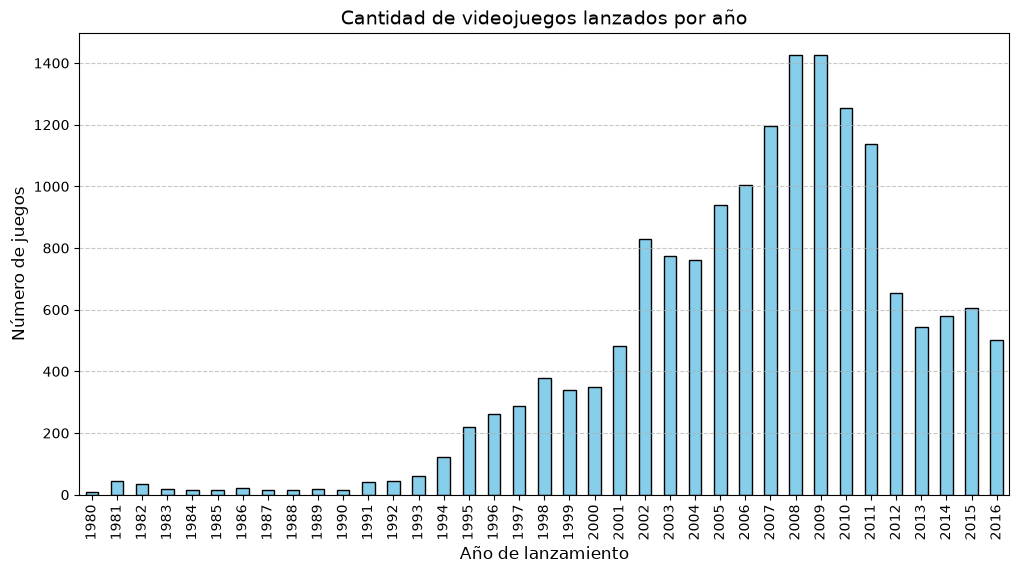

In [4]:
import matplotlib.pyplot as plt

# Contamos cuántos juegos se lanzaron por año y los ordenamos por índice (año cronológico)
games_per_year = df.groupby('year_of_release')['name'].count().sort_index()

# Graficamos la cantidad de lanzamientos por año
games_per_year.plot(kind='bar', figsize=(12, 6), color='skyblue', edgecolor='black')
plt.title('Cantidad de videojuegos lanzados por año', fontsize=14)
plt.xlabel('Año de lanzamiento', fontsize=12)
plt.ylabel('Número de juegos', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Análisis de la distribución de juegos por año

* **Tendencia histórica y picos de producción:** El volumen de juegos lanzados antes de 1995 es prácticamente nulo (menos de 50 juegos anuales en promedio, y casi cero hasta 1983), mientras que el período 2008-2009 representa el pico máximo con más de 1,400 lanzamientos anuales.
* **Significatividad de los períodos:** Incluir datos muy antiguos o dispersos sesgaría el comportamiento del mercado de videojuegos vigente; por tanto, es necesario enfocar el estudio en períodos representativos de la industria madura.
* **Definición de la ventana de estudio:** Tras evaluar el ciclo de vida comercial de las consolas (que suele rondar entre los 5 y 7 años), se determinó que la ventana relevante para modelar la campaña publicitaria de 2017 es el período **2014-2016**. Este período representa el ciclo activo y vigente de la industria, asegurando datos suficientemente robustos y libres de sesgos de generaciones obsoletas para un análisis confiable.

### 3.2 Evolución de ventas por plataforma

A continuación, analizaremos qué plataformas han acumulado mayores volúmenes de ventas históricas y cómo ha evolucionado su desempeño comercial a lo largo del tiempo. Esto nos permitirá identificar los ciclos de vida de las consolas y seleccionar un período de referencia adecuado para estudiar las tendencias recientes del mercado y orientar la planificación comercial de 2017.

Ventas totales por plataforma:


platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
Name: total_sales, dtype: float64

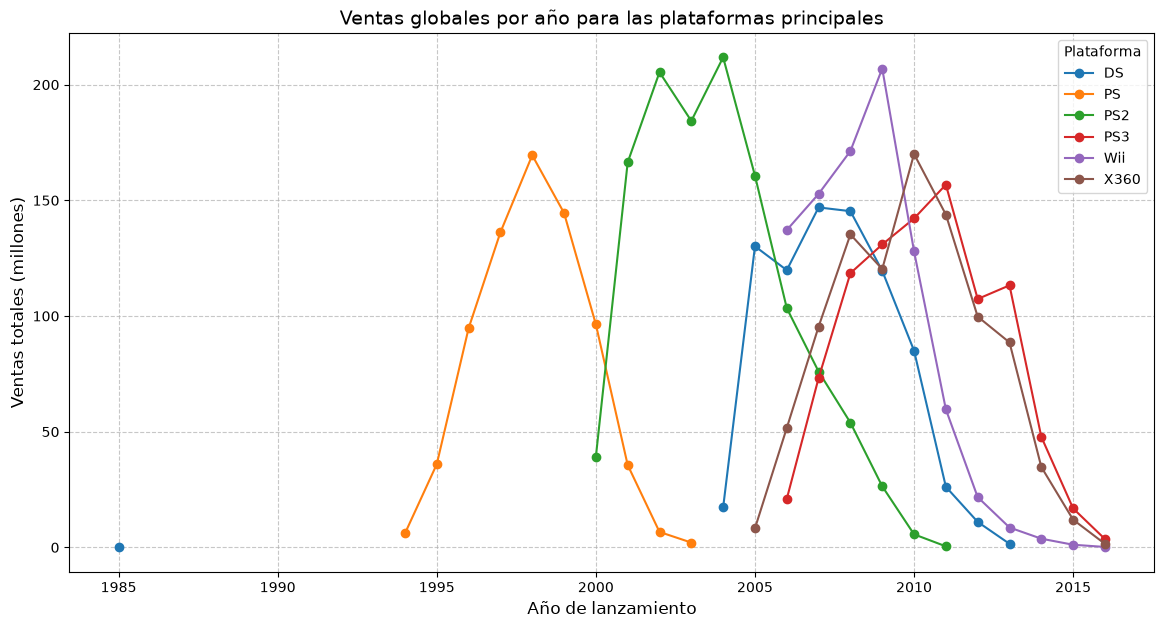

In [5]:
# Obtenemos las plataformas con mayores ventas globales históricas
top_platforms = df.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
print("Ventas totales por plataforma:")
display(top_platforms.head(10))

# Seleccionamos las principales plataformas con mayor volumen histórico para ver su comportamiento anual
platforms_to_plot = top_platforms.head(6).index.tolist()

# Creamos una tabla dinámica de ventas por plataforma y año, ordenando cronológicamente por índice
df_filtered_platforms = df[df['platform'].isin(platforms_to_plot)]
sales_by_year_platform = df_filtered_platforms.pivot_table(
    index='year_of_release',
    columns='platform',
    values='total_sales',
    aggfunc='sum'
).sort_index()

# Graficamos la evolución anual de las plataformas principales
sales_by_year_platform.plot(figsize=(14, 7), marker='o')
plt.title('Ventas globales por año para las plataformas principales', fontsize=14)
plt.xlabel('Año de lanzamiento', fontsize=12)
plt.ylabel('Ventas totales (millones)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Plataforma')
plt.show()

### Análisis de la evolución de ventas por plataforma

* **Plataformas líderes:** PS2 lidera con 1,255.77 millones de unidades vendidas históricamente, seguida por X360 (971.42 millones) y PS3 (939.65 millones). Estas tres plataformas concentran las mayores ventas globales acumuladas.
* **Ciclo de vida de plataformas:** El gráfico muestra claramente el ciclo de vida comercial de cada plataforma, el cual suele rondar entre los 5 y 10 años desde su surgimiento hasta su declive:
  * **PS2:** Período de crecimiento acelerado, alcanza su pico máximo en 2006-2007 (~200 millones de unidades) con una fuerte presencia en el mercado, seguido de un declive gradual hasta desaparecer alrededor de 2012.
  * **X360 y PS3:** Emergen con fuerza a mediados de los 2000, alcanzan picos importantes alrededor de 2008-2009 y mantienen presencia activa hasta la primera mitad de la década de 2010.
  * **Wii:** Consola de sobremesa con un ciclo intenso, alcanza su pico alrededor de 2008-2009 (~100 millones de unidades), seguido de un declive moderado hasta su desaparición del mercado activo hacia 2012.
  * **DS:** Plataforma portátil con presencia dominante entre 2008 y 2010, alcanzando picos cercanos a 100 millones de unidades. Mantiene presencia extendida hasta 2013 debido a su popularidad en distintos mercados.
* **Plataformas en declive:** Las plataformas clásicas o de generaciones anteriores muestran volúmenes nulos o mínimos en los años recientes, indicando el fin de sus ciclos comerciales.
* **Conclusión para la ventana de estudio:** Para el período seleccionado (2014-2016), las plataformas más relevantes y con actividad comercial vigente contrastan fuertemente con consolas pasadas como PS2 o Wii, que ya habían perdido presencia significativa en el mercado.

### 3.3 Filtrado de datos relevantes para la planificación de 2017

Basándonos en los gráficos anteriores, observamos que las plataformas presentan ciclos de vida comerciales que suelen extenderse durante varios años. Para orientar la planificación de la campaña publicitaria de 2017, descartaremos los años anteriores y nos enfocaremos en los datos a partir de 2014 (los tres años previos al período objetivo), donde se aprecian con mayor claridad las plataformas que mantienen actividad comercial, como PS4 y Xbox One.

Este período permite concentrar el análisis en las tendencias recientes del mercado, evitando que el comportamiento de generaciones anteriores de consolas domine las conclusiones y recomendaciones comerciales.

In [6]:
# Filtramos el dataset para trabajar solo desde el año 2014 en adelante 
df_recent = df[df['year_of_release'] >= 2014].copy()

# Verificamos las ventas globales por plataforma en este nuevo periodo reducido
recent_platforms = df_recent.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
print("Ventas totales por plataforma (2014-2016):")
display(recent_platforms)

Ventas totales por plataforma (2014-2016):


platform
PS4     288.15
XOne    140.36
3DS      86.68
PS3      68.18
X360     48.22
WiiU     42.98
PC       27.05
PSV      22.40
Wii       5.07
PSP       0.36
Name: total_sales, dtype: float64

### Análisis del período filtrado (2014-2016)

* **Plataformas dominantes en el período de estudio:** PS4 lidera con 288.15 millones de unidades vendidas, seguida de Xbox One con 140.36 millones. En conjunto, ambas plataformas acumulan 428.51 millones de unidades, aproximadamente el 58.7% de las ventas totales registradas entre las diez plataformas analizadas.
* **Presencia de plataformas en declive:** PS3 (68.18 millones) y X360 (48.22 millones) todavía registran ventas durante el período 2014-2016, aunque con volúmenes inferiores a los de sus años de mayor actividad comercial.
* **Plataformas portátiles:** 3DS (86.68 millones) mantiene una presencia importante, posicionándose como la tercera plataforma con mayores ventas del período y superando a PS3 y X360. Esto refleja la relevancia que todavía conservan los videojuegos portátiles, especialmente en mercados como Japón.
* **Base de datos resultante:** El dataset filtrado contiene registros correspondientes a diez plataformas con ventas durante 2014-2016, proporcionando una base de análisis adecuada para estudiar las tendencias recientes del mercado y formular recomendaciones comerciales para 2017.

### 3.4 Diagrama de caja para las ventas globales por plataforma
Ahora crearemos un diagrama de caja (*boxplot*) para comparar la distribución de las ventas globales de los juegos desglosados por plataforma en este periodo reciente.

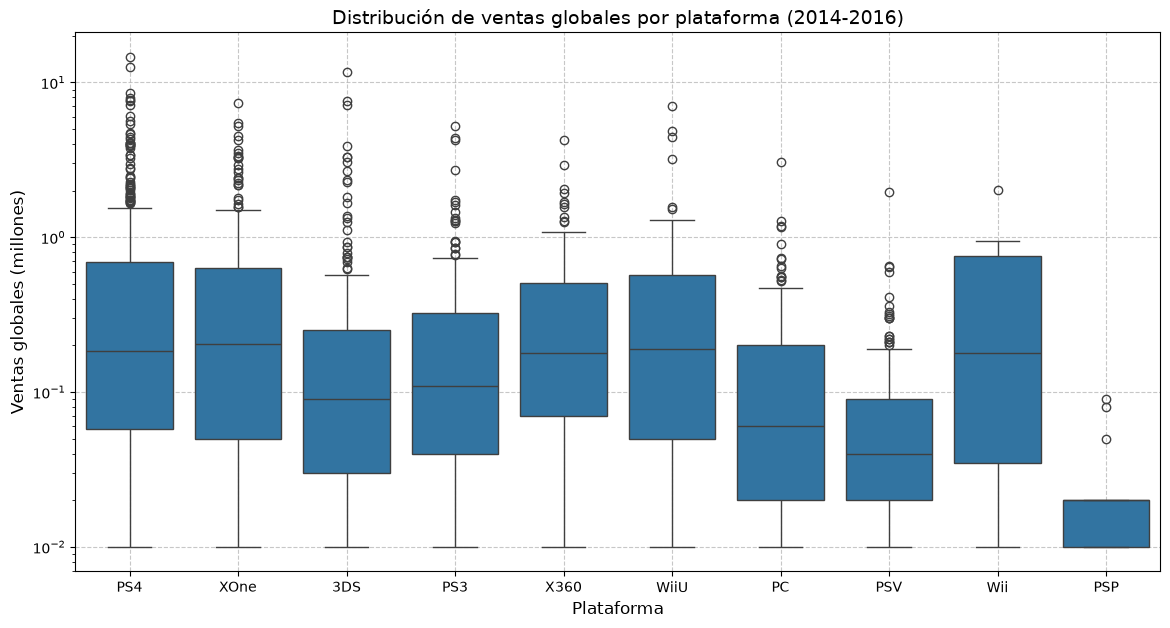

In [7]:
import seaborn as sns

# Creamos diagrama de caja para todas las plataformas en el período 2014-2016
plt.figure(figsize=(14, 7))
sns.boxplot(data=df_recent, x='platform', y='total_sales', order=recent_platforms.index)
plt.title('Distribución de ventas globales por plataforma (2014-2016)', fontsize=14)
plt.xlabel('Plataforma', fontsize=12)
plt.ylabel('Ventas globales (millones)', fontsize=12)
plt.yscale('log') # Usamos escala logarítmica (log) para visualizar el amplio rango de ventas (desde 0.01 hasta 10+ millones), permitiendo distinguir cajas comprimidas sin perder outliers superiores
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Análisis del diagrama de caja por plataforma

* **Diferencias en las distribuciones:** El diagrama muestra disparidades en las ventas entre plataformas. PS4 y Xbox One presentan medianas más altas (aproximadamente 0.3 y 0.2 millones de unidades respectivamente), lo que indica mayores ventas por título en comparación con varias de las demás plataformas.
* **Variabilidad y valores atípicos (outliers):** PS4 muestra mayor dispersión en las ventas, con numerosos valores atípicos superiores concentrados entre 1 y 15 millones de unidades, indicando que algunos títulos alcanzan ventas extraordinariamente altas. Xbox One presenta una distribución similar, aunque con una menor cantidad de valores atípicos extremos. Plataformas como 3DS y Wii también presentan valores atípicos significativos, aunque con medianas generales inferiores a las de las consolas de nueva generación.
* **Plataformas con menores medianas:** PSP, PC y PSV muestran distribuciones concentradas en valores bajos, con medianas cercanas a 0.01 millones de unidades. Esto indica que la mayoría de los títulos analizados en estas plataformas registraron ventas relativamente reducidas durante el período estudiado.
* **Conclusión:** PS4 y Xbox One destacan por sus medianas de ventas y la distribución de sus resultados comerciales en el período 2014-2016. Estos hallazgos respaldan su consideración entre las plataformas relevantes para el análisis y la planificación de 2017.

### 3.5 Relación entre las reseñas y las ventas (PS4)

Ahora investigaremos la relación entre las calificaciones de los críticos y de los usuarios y las ventas globales de una de las plataformas más representativas del período reciente: PS4.

Para ello, utilizaremos diagramas de dispersión y calcularemos los coeficientes de correlación correspondientes, con el propósito de identificar posibles asociaciones entre las valoraciones y el desempeño comercial de los videojuegos.

Correlación entre ventas y reseñas de críticos (PS4): 0.4019
Correlación entre ventas y reseñas de usuarios (PS4): -0.0432


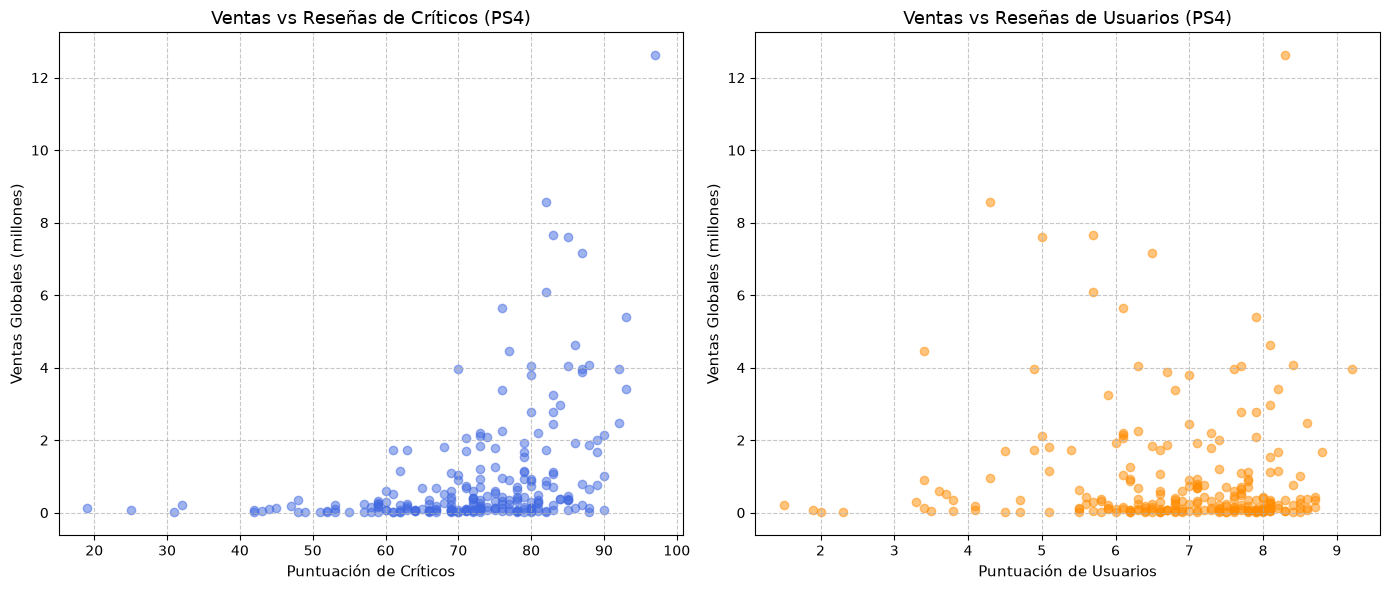

In [8]:
# Filtramos los datos exclusivamente para PS4 en el periodo reciente
ps4_df = df_recent[df_recent['platform'] == 'PS4'].dropna(subset=['critic_score', 'user_score'])

# Calculamos las correlaciones
corr_critic = ps4_df['total_sales'].corr(ps4_df['critic_score'])
corr_user = ps4_df['total_sales'].corr(ps4_df['user_score'])

print(f"Correlación entre ventas y reseñas de críticos (PS4): {corr_critic:.4f}")
print(f"Correlación entre ventas y reseñas de usuarios (PS4): {corr_user:.4f}")

# Creamos gráficos de dispersión lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Ventas vs Critic Score

axes[0].scatter(ps4_df['critic_score'], ps4_df['total_sales'], alpha=0.5, color='royalblue')
axes[0].set_title('Ventas vs Reseñas de Críticos (PS4)', fontsize=13)
axes[0].set_xlabel('Puntuación de Críticos', fontsize=11)
axes[0].set_ylabel('Ventas Globales (millones)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.7)


# Gráfico 2: Ventas vs User Score
axes[1].scatter(ps4_df['user_score'], ps4_df['total_sales'], alpha=0.5, color='darkorange')
axes[1].set_title('Ventas vs Reseñas de Usuarios (PS4)', fontsize=13)
axes[1].set_xlabel('Puntuación de Usuarios', fontsize=11)
axes[1].set_ylabel('Ventas Globales (millones)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Conclusiones sobre la relación entre las reseñas y las ventas (PS4)

* **Reseñas de críticos:** Presentan una correlación positiva moderada (0.4019) con las ventas globales. Esto indica que, dentro de los videojuegos analizados para PS4, las puntuaciones más altas de los críticos tienden a estar asociadas con mayores volúmenes de ventas.
* **Reseñas de usuarios:** Presentan una correlación lineal prácticamente nula (-0.0432). Esto indica que, en la muestra analizada, no se observa una asociación lineal clara entre las calificaciones de los usuarios y las ventas globales.
* **Interpretación final:** Los resultados muestran que las valoraciones de los críticos presentan una asociación más clara con las ventas de PS4 que las calificaciones de los usuarios. Sin embargo, estas correlaciones no permiten establecer relaciones de causalidad ni determinar por sí solas qué otros factores explican el desempeño comercial de los videojuegos.

### 3.6 Análisis de las ventas y distribución de videojuegos por género

A continuación, analizaremos el volumen total de ventas y la mediana de ventas por videojuego para cada género durante el período 2014-2016.

También examinaremos la cantidad de títulos disponibles en cada categoría, con el propósito de identificar los géneros con mayor presencia comercial y aquellos que presentan un mejor desempeño en términos de ventas por título.

Análisis de ventas por género (2014-2016):


,total_sales,median_sales,count
genre,,,
Action,199.36,0.090,619
Shooter,170.94,0.515,128
Sports,109.48,0.180,161
Role-Playing,101.44,0.110,221
Misc,37.55,0.090,113
Fighting,28.22,0.125,60
Racing,27.52,0.090,69
Platform,18.09,0.140,38
Adventure,17.55,0.030,185


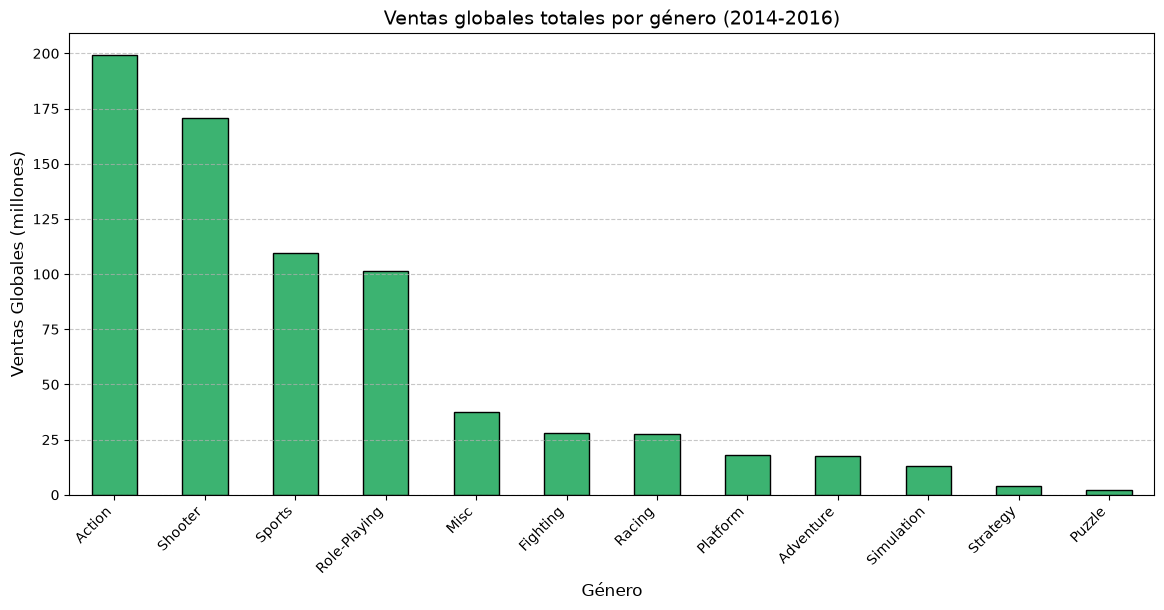

In [9]:
# Analizamos la cantidad de juegos y las ventas totales y mediana por género
genre_analysis = df_recent.groupby('genre').agg(
    total_sales=('total_sales', 'sum'),
    median_sales=('total_sales', 'median'),
    count=('name', 'count')
).sort_values(by='total_sales', ascending=False)

print("Análisis de ventas por género (2014-2016):")
display(genre_analysis)

# Graficamos las ventas totales por género
plt.figure(figsize=(14,6))
genre_analysis['total_sales'].plot(kind='bar', color='mediumseagreen', edgecolor='black')
plt.title('Ventas globales totales por género (2014-2016)', fontsize=14)
plt.xlabel('Género', fontsize=12)
plt.ylabel('Ventas Globales (millones)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Conclusiones sobre el análisis de géneros (2014-2016)

* **Action lidera en volumen absoluto de ventas:** Action registra 199.36 millones de unidades vendidas en total, la cifra más alta entre los géneros analizados. Este resultado está relacionado con la gran cantidad de títulos lanzados (619 juegos), lo que refleja un elevado volumen comercial acumulado.
* **Shooter destaca por su mediana de ventas por título:** Presenta la mediana más alta, con 0.515 millones de unidades por videojuego. Esto indica que el título ubicado en el punto medio de la distribución de ventas de este género supera la mediana de los demás géneros analizados. Cabe destacar que la mediana no representa el promedio de ventas ni permite determinar la rentabilidad económica.
* **Sports y Role-Playing mantienen una presencia significativa:** Sports registra 109.48 millones de unidades vendidas y Role-Playing 101.44 millones. Ambos géneros mantienen volúmenes comerciales importantes, con medianas de 0.180 y 0.110 millones de unidades por título, respectivamente.
* **Fighting muestra un volumen comercial menor:** Aunque no lidera en ventas acumuladas (28.22 millones de unidades), presenta una mediana de 0.125 millones por título y cuenta con 60 videojuegos en el período analizado.
* **Géneros con menor volumen de ventas:** Géneros como Platform (18.09 millones de unidades), Strategy (3.96 millones) y Puzzle (2.21 millones) registran volúmenes comerciales considerablemente inferiores durante el período estudiado.
* **Recomendación comercial:** Para la planificación de 2017, Action representa una alternativa destacada por su volumen acumulado de ventas, mientras que Shooter sobresale por su mediana de ventas por videojuego. Sports y Role-Playing también constituyen opciones relevantes, especialmente al considerar las preferencias de los consumidores y las diferencias entre regiones.

En conjunto, estos resultados muestran que el volumen total de ventas y la mediana de ventas por título ofrecen perspectivas complementarias para evaluar el desempeño comercial de cada género.

## 4. Perfiles de usuario por región (NA, EU, JP)
Para cada región (Norteamérica, Europa y Japón), analizaremos las 5 plataformas principales, los 5 géneros principales y el impacto de la clasificación ESRB en las ventas.


### 4.1 Top 5 plataformas por región
A continuación, determinaremos cuáles son las cinco plataformas con mayor volumen de ventas en cada región para identificar qué consolas dominan en cada mercado geográfico.

In [10]:
# Definimos las regiones a analizar
regions = ['na_sales', 'eu_sales', 'jp_sales']
region_names = ['Norteamérica (NA)', 'Europa (EU)', 'Japón (JP)']

# Analizamos las 5 plataformas principales por región
for reg, name in zip(regions, region_names):
    top_platforms = df_recent.groupby('platform')[reg].sum().reset_index()
    top_platforms = top_platforms.sort_values(by=reg, ascending=False).head(5)

    print(f"Top 5 plataformas en {name}:")
    display(top_platforms)

Top 5 plataformas en Norteamérica (NA):


,platform,na_sales
3,PS4,98.61
9,XOne,81.27
8,X360,28.30
0,3DS,22.64
2,PS3,22.05


Top 5 plataformas en Europa (EU):


,platform,eu_sales
3,PS4,130.04
9,XOne,46.25
2,PS3,25.54
1,PC,17.97
0,3DS,16.12


Top 5 plataformas en Japón (JP):


,platform,jp_sales
0,3DS,44.24
3,PS4,15.02
5,PSV,14.54
2,PS3,11.22
7,WiiU,7.31


### Análisis de plataformas dominantes por región

* **Norteamérica (NA):** PS4 lidera con 98.61 millones de unidades vendidas, seguida de Xbox One (81.27 millones). Ambas plataformas destacan ampliamente en el mercado durante el período analizado. X360 (28.30 millones) y 3DS (22.64 millones) también mantienen presencia comercial, junto con PS3 (22.05 millones).
* **Europa (EU):** PS4 lidera con 130.04 millones de unidades, seguida de Xbox One (46.25 millones). La diferencia entre ambas plataformas es considerable. PS3 (25.54 millones), PC (17.97 millones) y 3DS (16.12 millones) completan las cinco principales plataformas.
* **Japón (JP):** Presenta un comportamiento diferente, con 3DS liderando las ventas (44.24 millones), seguida de PS4 (15.02 millones) y PSV (14.54 millones). Las plataformas portátiles 3DS y PSV mantienen una presencia destacada en este mercado.
* **Diferencias clave entre regiones:**
  * **NA y EU:** PS4 y Xbox One ocupan las primeras posiciones en ventas.
  * **JP:** Nintendo 3DS lidera ampliamente, mientras que PSV también aparece entre las principales plataformas.
  * **Xbox One:** Tiene una presencia importante en Norteamérica y Europa, pero no figura entre las cinco plataformas con mayores ventas en Japón.
* **Conclusión regional:** Los resultados muestran diferencias claras en las plataformas preferidas entre regiones. Estas variaciones deben considerarse al definir estrategias de marketing y distribución para 2017.

### 4.2 Top 5 géneros por región
A continuación, analizaremos cuáles son los cinco géneros más populares en cada mercado para identificar diferencias en las preferencias de los jugadores.

In [11]:
# Analizamos los 5 géneros principales por región para identificar diferencias en preferencias de jugadores
for reg, name in zip(regions, region_names):
    top_genres = df_recent.groupby('genre')[reg].sum().reset_index()
    top_genres = top_genres.sort_values(by=reg, ascending=False).head(5)
    
    print(f"Top 5 géneros en {name}:")
    display(top_genres)

Top 5 géneros en Norteamérica (NA):


,genre,na_sales
8,Shooter,79.02
0,Action,72.53
10,Sports,46.13
7,Role-Playing,33.47
3,Misc,15.05


Top 5 géneros en Europa (EU):


,genre,eu_sales
0,Action,74.68
8,Shooter,65.52
10,Sports,45.73
7,Role-Playing,28.17
6,Racing,14.13


Top 5 géneros en Japón (JP):


,genre,jp_sales
7,Role-Playing,31.16
0,Action,29.58
2,Fighting,6.37
3,Misc,5.61
8,Shooter,4.87


### Análisis de géneros dominantes por región

* **Norteamérica (NA):** Shooter lidera con 79.02 millones de unidades vendidas, seguido de Action (72.53 millones). En conjunto, estos géneros representan una parte importante del volumen comercial regional. Sports (46.13 millones) ocupa el tercer lugar, mientras que Role-Playing registra 33.47 millones.
* **Europa (EU):** Action domina con 74.68 millones de unidades, seguido de Shooter (65.52 millones). Sports (45.73 millones) mantiene la tercera posición. Racing (14.13 millones) aparece entre los cinco géneros principales de la región.
* **Japón (JP):** Role-Playing lidera con 31.16 millones de unidades vendidas, seguido de Action (29.58 millones). Fighting (6.37 millones) y Misc (5.61 millones) también aparecen entre los cinco géneros principales, mientras que Shooter registra 4.87 millones.
* **Diferencias clave:**
  * **NA y EU:** Shooter y Action ocupan las primeras posiciones, acompañados por una presencia importante de Sports.
  * **JP:** Role-Playing ocupa el primer lugar y Fighting aparece entre los cinco géneros principales.
  * **Sports:** Mantiene una presencia destacada en Norteamérica y Europa, pero no aparece entre los cinco principales géneros de Japón.
  * **Racing:** Figura entre los cinco principales géneros europeos, pero no en los de Norteamérica ni Japón.
* **Conclusión:** Las diferencias en la distribución de ventas por género muestran que las preferencias del mercado no son uniformes entre regiones. Por ello, resulta conveniente considerar las características de cada mercado al seleccionar los géneros y títulos que integrarán las campañas comerciales de 2017.

### 4.3 Distribución de ventas según la clasificación ESRB

Analizaremos cómo se distribuyen las ventas de videojuegos entre las distintas categorías de clasificación ESRB (Entertainment Software Rating Board) en Norteamérica, Europa y Japón.

El objetivo es identificar diferencias regionales en las categorías registradas y observar qué grupos concentran mayores volúmenes de ventas durante el período 2014-2016.

In [12]:
# Rellenamos los valores nulos de la clasificación con 'Sin clasificar' para evitar perder datos
df_recent['rating'] = df_recent['rating'].fillna('Sin clasificar')

# Analizamos las ventas por clasificación ESRB en cada región
for reg, name in zip(regions, region_names):
    esrb_sales = df_recent.groupby('rating')[reg].sum().reset_index()
    esrb_sales = esrb_sales.sort_values(by=reg, ascending=False)
    
    print(f"Ventas por clasificación ESRB en {name}:")
    display(esrb_sales)

Ventas por clasificación ESRB en Norteamérica (NA):


,rating,na_sales
2,M,96.42
3,Sin clasificar,64.72
0,E,50.74
4,T,38.95
1,E10+,33.23


Ventas por clasificación ESRB en Europa (EU):


,rating,eu_sales
2,M,93.44
3,Sin clasificar,58.95
0,E,58.06
4,T,34.07
1,E10+,26.16


Ventas por clasificación ESRB en Japón (JP):


,rating,jp_sales
3,Sin clasificar,56.90
4,T,14.78
0,E,8.94
2,M,8.01
1,E10+,4.46


### Análisis de la distribución de ventas según la clasificación ESRB

* **Norteamérica (NA):** Las ventas están lideradas por M (Mature / 17+) con 96.42 millones de unidades, aproximadamente el 33.9% de las ventas regionales registradas por categoría. En segundo lugar, la categoría "Sin clasificar" registra 64.72 millones de unidades (22.8%). Cierra el podio E (Everyone), con 50.74 millones (17.9%). Estos resultados muestran una presencia destacada de videojuegos clasificados como M en el mercado norteamericano.
* **Europa (EU):** Europa presenta un comportamiento similar al de Norteamérica, con M liderando las ventas (93.44 millones de unidades), aproximadamente el 34.5% del total regional. La categoría "Sin clasificar" registra 58.95 millones (21.8%), una cifra cercana a E, con 58.06 millones (21.4%).
* **Japón (JP):** Presenta un patrón diferente. La categoría "Sin clasificar" domina las ventas con 56.90 millones de unidades, aproximadamente el 61.1% del total regional. Entre los títulos que sí cuentan con una clasificación ESRB registrada, T (Teen) destaca con 14.78 millones de unidades, mientras que M registra 8.01 millones. Es importante señalar que los valores ausentes en `rating` únicamente indican que el dataset no proporciona una clasificación ESRB para esos títulos; no permiten determinar si cuentan con una clasificación de otro sistema regional.
* **Conclusión regional:** Las categorías de clasificación registradas muestran diferencias entre los mercados analizados. Norteamérica y Europa presentan un predominio de la categoría M, mientras que Japón concentra una proporción considerable de sus ventas en títulos sin clasificación ESRB registrada. Para la planificación de 2017, estos resultados justifican considerar las diferencias regionales y evitar interpretar los valores ausentes como evidencia de una clasificación específica.

## 5. Pruebas de hipótesis
En esta sección realizaremos pruebas estadísticas para comprobar ciertas hipótesis sobre el comportamiento de los usuarios en relación con las plataformas y los géneros de videojuegos.

### 5.1 Calificaciones promedio entre las plataformas Xbox One y PC
Evaluaremos si existen diferencias significativas entre las calificaciones promedio de los usuarios para la consola Xbox One y la plataforma PC.


* **Hipótesis nula ($H_0$):** Las calificaciones promedio de los usuarios para Xbox One y PC son iguales.
* **Hipótesis alternativa ($H_1$):** Las calificaciones promedio de los usuarios para Xbox One y PC son diferentes.


In [13]:
from scipy import stats as st

# Nivel de significancia (alfa)
alpha = 0.05

# --- Prueba de hipótesis 1: Xbox One vs PC ---
xbox_one_scores = df_recent.loc[
    df_recent['platform'] == 'XOne', 'user_score'
].dropna()

pc_scores = df_recent.loc[
    df_recent['platform'] == 'PC', 'user_score'
].dropna()

results_h1 = st.ttest_ind(
    xbox_one_scores,
    pc_scores,
    equal_var=False
)

print(f"p-value Hipótesis 1 (Xbox One vs PC): {results_h1.pvalue}")

if results_h1.pvalue < alpha:
    print(
        "Resultado: Rechazamos la hipótesis nula. "
        "Existe evidencia estadística de una diferencia "
        "entre las calificaciones promedio."
    )
else:
    print(
        "Resultado: No podemos rechazar la hipótesis nula. "
        "No se encontró evidencia estadística suficiente "
        "de una diferencia entre las calificaciones promedio."
    )

p-value Hipótesis 1 (Xbox One vs PC): 0.11601398086668831
Resultado: No podemos rechazar la hipótesis nula. No se encontró evidencia estadística suficiente de una diferencia entre las calificaciones promedio.


### Resultados e Interpretación - Hipótesis 1

* **P-value obtenido:** `0.1160` (un valor mayor que nuestro nivel de significancia \(\alpha = 0.05\)).
* **Decisión estadística:** No podemos rechazar la hipótesis nula.
* **Interpretación:** Con un nivel de significancia del 5%, no existe evidencia estadística suficiente para afirmar que las calificaciones promedio de los usuarios difieran significativamente entre Xbox One y PC durante el período analizado. Aunque se observan variaciones entre las muestras, estas no son suficientes para establecer una diferencia estadísticamente significativa.
* **Conclusión práctica:** Con base en los resultados de esta prueba, no se encontró evidencia suficiente de una diferencia en las calificaciones promedio de los usuarios entre Xbox One y PC para el período 2014-2016. Para la planificación de 2017, este resultado puede servir como referencia, aunque no demuestra que ambas plataformas tengan calificaciones idénticas o que las preferencias de sus usuarios sean equivalentes.

### 5.2 Calificaciones promedio entre los géneros Acción y Deportes
Comprobaremos si las calificaciones promedio de los usuarios varían de forma significativa entre el género de Acción y el género de Deportes.

* **Hipótesis nula ($H_0$):** Las calificaciones promedio de los usuarios para los géneros Acción y Deportes son iguales.
* **Hipótesis alternativa ($H_1$):** Las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son diferentes.

In [14]:
# --- Prueba de hipótesis 2: Acción vs Deportes ---

action_scores = df_recent.loc[
    df_recent['genre'] == 'Action', 'user_score'
].dropna()

sports_scores = df_recent.loc[
    df_recent['genre'] == 'Sports', 'user_score'
].dropna()

results_h2 = st.ttest_ind(
    action_scores,
    sports_scores,
    equal_var=False
)

print(f"p-value Hipótesis 2 (Acción vs Deportes): {results_h2.pvalue}")

if results_h2.pvalue < alpha:
    print(
        "Resultado: Rechazamos la hipótesis nula. "
        "Existe evidencia estadística de una diferencia "
        "entre las calificaciones promedio."
    )
else:
    print(
        "Resultado: No podemos rechazar la hipótesis nula. "
        "No se encontró evidencia estadística suficiente "
        "de una diferencia entre las calificaciones promedio."
    )

p-value Hipótesis 2 (Acción vs Deportes): 1.1825550382644427e-14
Resultado: Rechazamos la hipótesis nula. Existe evidencia estadística de una diferencia entre las calificaciones promedio.


### Resultados e Interpretación - Hipótesis 2

* **P-value obtenido:** `1.1825e-14` (un valor extraordinariamente pequeño, mucho menor que nuestro nivel de significancia \(\alpha = 0.05\)).
* **Decisión estadística:** Rechazamos la hipótesis nula.
* **Interpretación:** Con un nivel de significancia del 5%, existe evidencia estadística muy fuerte para afirmar que las calificaciones promedio de los usuarios difieren significativamente entre los géneros de Acción y Deportes durante el período 2014-2016.
* **Análisis comparativo:** A diferencia de la primera prueba, en esta comparación sí encontramos evidencia estadística suficiente para identificar una diferencia entre las calificaciones promedio de los dos grupos analizados. Sin embargo, este resultado no permite concluir por sí solo que el género tenga un impacto comercial mayor que la plataforma, ni determina cuál de los dos géneros obtiene mejores calificaciones.
* **Conclusión práctica:** Los resultados muestran que las valoraciones promedio de los usuarios presentan diferencias estadísticamente significativas entre Acción y Deportes. Para la planificación de 2017, este hallazgo respalda la importancia de considerar el género como una variable relevante al estudiar las preferencias de los consumidores.

### Síntesis de ambas pruebas de hipótesis

Las dos pruebas estadísticas permitieron evaluar si existen diferencias significativas en las calificaciones promedio de los usuarios entre determinados grupos de plataformas y géneros:

* **Comparación de plataformas:** En la prueba entre Xbox One y PC no se encontró evidencia estadística suficiente para afirmar que las calificaciones promedio de los usuarios sean diferentes (H1: p = 0.1160).
* **Comparación de géneros:** En la prueba entre Acción y Deportes se encontró evidencia estadística muy fuerte de una diferencia entre las calificaciones promedio de ambos géneros (H2: p = 1.18e-14).

**Implicación para la planificación de 2017:** Los resultados muestran que las diferencias en las calificaciones promedio dependen de los grupos comparados. En particular, se identificó una diferencia estadísticamente significativa entre los géneros de Acción y Deportes, mientras que no se encontró evidencia suficiente de una diferencia entre Xbox One y PC. Estos hallazgos pueden complementar el análisis comercial y ayudar a considerar tanto las plataformas como los géneros al estudiar las preferencias de los consumidores.

### 6. Conclusión general

A lo largo de este proyecto se analizaron datos históricos de la industria global de los videojuegos para identificar patrones comerciales, tendencias de consumo y diferencias regionales que permitan orientar la planificación de la campaña publicitaria de 2017.

Los principales hallazgos del análisis son los siguientes:

1. **Tendencias temporales y período de estudio:** Tras el crecimiento de la industria alrededor de 2008-2011, los lanzamientos globales mostraron una tendencia descendente. Para estudiar las condiciones más recientes del mercado y orientar las recomendaciones para 2017, se seleccionó el período 2014-2016, considerando las plataformas que mantenían actividad comercial durante esos años.

2. **Plataformas y géneros dominantes:**
   * A nivel global, **PS4 y Xbox One** destacan en los mercados occidentales, mientras que **Nintendo 3DS** mantiene una presencia importante en Japón.
   * En cuanto a géneros, **Action** lidera en volumen total de ventas (199.36 millones de unidades vendidas), mientras que **Shooter** presenta la mediana de ventas más alta (0.515 millones de unidades por título). Esta diferencia muestra la importancia de distinguir entre el volumen acumulado de ventas y el comportamiento de las ventas por videojuego.

3. **Perfiles regionales:**
   * **Norteamérica y Europa:** Presentan preferencias relativamente similares, con una presencia destacada de PS4 y Xbox One y una fuerte participación de géneros como *Shooter*, *Action* y *Sports*. También registran un volumen importante de ventas de videojuegos clasificados como M.
   * **Japón:** Presenta preferencias diferentes, con una mayor presencia de Nintendo 3DS y una clara preferencia por los juegos de rol (*Role-Playing*). Además, una proporción considerable de sus ventas corresponde a títulos sin clasificación ESRB registrada en el dataset.

4. **Pruebas de hipótesis:**
   * En la comparación entre Xbox One y PC no se encontró evidencia estadística suficiente para afirmar que las calificaciones promedio de los usuarios sean diferentes (p = 0.1160).
   * En contraste, la comparación entre los géneros de *Acción* y *Deportes* mostró una diferencia estadísticamente significativa en las calificaciones promedio de los usuarios (p = 1.1825e-14).

**Recomendación final:**

Para la planificación comercial de 2017, resulta conveniente priorizar las plataformas con una presencia sólida en cada mercado y adaptar las estrategias de marketing a las preferencias regionales. Action representa una oportunidad destacada por su volumen acumulado de ventas, mientras que Shooter sobresale por su mediana de ventas por título. Asimismo, las preferencias particulares de Japón justifican una estrategia diferenciada respecto a Norteamérica y Europa.

En conjunto, este análisis proporciona una base cuantitativa para orientar las decisiones de marketing y distribución, aprovechando las tendencias históricas del mercado y las preferencias observadas de los consumidores.